# 11 · Does the zero-frequency rule hold at other loads and slice mixes?

**The rule (notebooks 09–10).** For a sustained fault, the value of coupling the slices is set by their coherence at frequency zero. A first-order prediction of the gain over the best single-slice detector is
$$G_{\text{DC}} = \frac{d^\top \Sigma_{LR}^{-1} d}{\max_j d_j^2 / \Sigma_{LR,jj}},$$
where $d$ is the fault's shift in the whitened latencies and $\Sigma_{LR}$ the long-run covariance. For a fault in slice $j$ alone this reduces to $1/(1-R^2_{j,\text{DC}})$. The instantaneous version uses $\Sigma$ instead of $\Sigma_{LR}$. In the default setting, the VAR-whitened bank's realised gain (18.6–24.2×) matched $G_{\text{DC}} \approx 20$. One setting proves little, so here we test the rule in five.

**Settings** (`configs/sim_*.yaml`; all illustrative assumptions):

| setting | what changes | offered load |
|---|---|---|
| `default` | reference (notebooks 03–10) | 56% |
| `high_load` | same mix, larger eMBB bursts | 72% |
| `new_mix` | weights 0.3/0.3/0.4, 2× URLLC and mMTC traffic, slow eMBB bursts (1 s on, 1.5 s off) | 70% |
| `light_load` | smaller eMBB bursts, steadier capacity (5% variation) | 38% |
| `control` | constant capacity, Poisson eMBB: **no shared slow noise** | 38% |

**The test.** In each setting:
1. Fit the fault-free models and calibrate four latency detectors to ARL 1000 windows: per-slice CUSUM, the bank on $\Sigma$, the bank on $\Sigma_{LR}$, and the bank on VAR innovations.
2. Run the three slice-local faults at five strengths, with the same seeds in every setting.
3. Measure the realised gain (per-slice mean delay ÷ VAR-bank mean delay) at the weakest strength where per-slice detection finds at least 80% of faults.
4. Compare it with $G_{\text{DC}}$ and the instantaneous prediction, both computed from that fault's *measured* shift $d$.

The rule passes if it predicts the gain where coupling matters, and predicts *no* gain in the control.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import (CUSUM, CUSUMBank, StreamModel, VARModel, candidate_directions, long_run_cov,
                               stream_array)
from slicead.eval import calibrate_bank, calibrate_per_stream, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-10, in every setting
OUT = Path("../results/11_second_load")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"11_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"11_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"11_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

SETTINGS = ["default", "high_load", "new_mix", "light_load", "control"]
NICE_SET = {"default": "default", "high_load": "high load", "new_mix": "new mix", "light_load": "light load",
            "control": "control"}
COLOR = {"default": BLUE, "high_load": ORANGE, "new_mix": AQUA, "light_load": YELLOW, "control": MUTED}
SLICES = ["eMBB", "URLLC", "mMTC"]
LAT = [(s, "latency_ms") for s in SLICES]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]
SCEN = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
ALL = list(SCEN)
LOCAL = ["urllc_surge", "mmtc_storm", "urllc_weight_misconfig"]
NICE = {"urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm", "urllc_weight_misconfig": "URLLC weight misconfig."}
DETS = ["per-slice", "bank, Sigma", "bank, Sigma_LR", "bank, VAR"]

def pred_gain(d, S):
    """First-order gain of coupling for shift d under noise covariance S: coupled rate / best single-slice rate."""
    return (d @ np.linalg.solve(S, d)) / np.max(d**2 / np.diag(S))

## 1. One function per setting

`run_setting` does, for one configuration:
- simulates training (8 × 300 s) and calibration (32 × 300 s) runs;
- fits the AR(1) and VAR models;
- estimates $\Sigma$, $\Sigma_{LR}$ ($L = 50$) and the VAR-implied $\Sigma_{LR}$;
- calibrates the four detectors;
- runs the local-fault sweep, keeping each case's measured shift $d$ (post-fault mean of $z$, from 2 s after the change, minus the pre-fault mean).

It is the code of notebook 10, restricted to latency and the local faults.

In [2]:
def run_setting(name):
    t0 = time.time()
    cfg = load_config(f"../configs/sim_{name}.yaml")
    train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
    Xtr = stream_array(train, LAT)
    Xcal = stream_array(simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1), LAT)
    ar1 = StreamModel().fit(Xtr)
    var = VARModel(max_p=30).fit(Xtr)
    Ztr, Zcal, Vcal = ar1.whiten(Xtr), ar1.whiten(Xcal), var.whiten(Xcal)
    Sigma = np.corrcoef(Ztr.reshape(-1, 3).T)
    SLR = long_run_cov(Ztr, 50)
    Ai = np.linalg.inv(var.dc_gain)
    SLR_var = Ai @ (var.Sigma_e * np.outer(var.sd_e, var.sd_e)) @ Ai.T
    C = candidate_directions(3)
    det = {}
    d = CUSUM(0.5); det["per-slice"] = (d, calibrate_per_stream(d, Zcal, TARGET_ARL)[0], "z")
    d = CUSUMBank(C, Sigma); det["bank, Sigma"] = (d, calibrate_bank(d, Zcal, TARGET_ARL)[0], "z")
    d = CUSUMBank(C, SLR); det["bank, Sigma_LR"] = (d, calibrate_bank(d, Zcal, TARGET_ARL)[0], "z")
    d = CUSUMBank(var.residual_directions(C), var.Sigma_e); det["bank, VAR"] = (d, calibrate_bank(d, Vcal, TARGET_ARL)[0], "v")
    rows, shifts = [], {}
    for scen in LOCAL:
        i = ALL.index(scen)
        for j, s in enumerate(STRENGTHS):
            res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + j,
                           faults=[Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in SCEN[scen]])
            X = stream_array(res, LAT)
            inp = {"z": ar1.whiten(X), "v": var.whiten(X)}
            nu = res.fault_window
            shifts[(scen, s)] = inp["z"][:, nu + 20:].mean(axis=(0, 1)) - inp["z"][:, :nu].mean(axis=(0, 1))
            for dn, (dt, c, key) in det.items():
                t, _ = first_alarms(dt, inp[key], c)
                rows.append(dict(setting=name, scenario=scen, strength=s, detector=dn,
                                 **summarize_delays(t, nu, HORIZON_W, res.window_s)))
    info = dict(load=cfg.offered_load(), utilisation=train.utilisation.mean(),
                latency_ms=Xtr.mean(axis=(0, 1)), var_p=var.p)
    print(f"{name}: {time.time() - t0:.0f} s")
    return dict(info=info, Ztr=Ztr, Sigma=Sigma, SLR=SLR, SLR_var=SLR_var, sweep=pd.DataFrame(rows), shifts=shifts)

R = {name: run_setting(name) for name in SETTINGS}
sweep = pd.concat([R[n]["sweep"] for n in SETTINGS], ignore_index=True)
sweep.to_csv(OUT / "sweep.csv", index=False)

default: 441 s


high_load: 278 s


new_mix: 274 s


light_load: 286 s


control: 274 s


## 2. The settings and their coherence

For each setting: load, mean latencies, VAR order, and the single-slice coupling gain $\Sigma_{jj}(\Sigma^{-1})_{jj}$ for URLLC and mMTC under three noise covariances: instantaneous, zero-frequency ($L = 50$), and VAR-implied zero-frequency.

In [3]:
def single(S, j):
    return S[j, j] * np.linalg.inv(S)[j, j]

rows = []
for n in SETTINGS:
    r, inf = R[n], R[n]["info"]
    rows.append(dict(setting=NICE_SET[n], load=inf["load"], utilisation=inf["utilisation"],
                     lat_eMBB=inf["latency_ms"][0], lat_URLLC=inf["latency_ms"][1], lat_mMTC=inf["latency_ms"][2],
                     VAR_p=inf["var_p"],
                     inst_URLLC=single(r["Sigma"], 1), inst_mMTC=single(r["Sigma"], 2),
                     DC_URLLC=single(r["SLR"], 1), DC_mMTC=single(r["SLR"], 2),
                     DCvar_URLLC=single(r["SLR_var"], 1), DCvar_mMTC=single(r["SLR_var"], 2)))
settings = pd.DataFrame(rows)
settings.to_csv(OUT / "settings.csv", index=False)
pd.set_option("display.width", 220)
settings.round(2)

,setting,load,utilisation,lat_eMBB,lat_URLLC,lat_mMTC,VAR_p,inst_URLLC,inst_mMTC,DC_URLLC,DC_mMTC,DCvar_URLLC,DCvar_mMTC
0,default,0.56,0.55,8.40,0.04,0.19,3,2.11,2.31,20.13,21.58,26.05,27.97
1,high load,0.72,0.67,18.97,0.05,0.20,3,1.40,1.51,14.94,14.72,30.11,30.36
2,new mix,0.70,0.60,14.77,0.08,0.19,2,1.77,1.98,20.14,21.15,60.40,60.92
3,light load,0.38,0.38,0.36,0.04,0.17,3,3.48,4.53,18.01,23.95,19.57,25.85
4,control,0.38,0.38,0.35,0.04,0.19,1,1.02,1.02,1.00,1.01,1.01,1.02


**What the settings look like**

- **Loads span 38–72%,** and eMBB latency spans 0.35–19 ms. URLLC and mMTC latency stay below 0.2 ms everywhere, since their weights cover their traffic.
- **In the four settings with shared slow noise, the instantaneous gain is small** (1.4–4.5) **and the zero-frequency gain large** (15–24 with $L = 50$).
- **In the control, every gain is 1.0:** without bursts or capacity drift, the slices share no noise at all.
- **The two zero-frequency estimates agree in default and light load, but not in high load and the new mix.** There the VAR-implied gain is 2–3× the Bartlett one (about 30 and 60, against 15 and 20). In those settings the slow eMBB bursts push $R^2_{\text{DC}}$ to 0.97–0.98, where $1/(1-R^2)$ is ill-conditioned: small differences in $R^2$ give large differences in the gain.

**Coherence against time-scale.** $\Sigma_{LR}$ estimated with $L$ Bartlett lags is exactly $n$ times the covariance of $n$-window averages, with $n = L + 1$. So the single-slice gain computed from it, as a function of $n$, shows how the cross-slice coherence builds up as noise is averaged over longer times. $n = 1$ is the instantaneous gain; large $n$ approaches the zero-frequency gain.

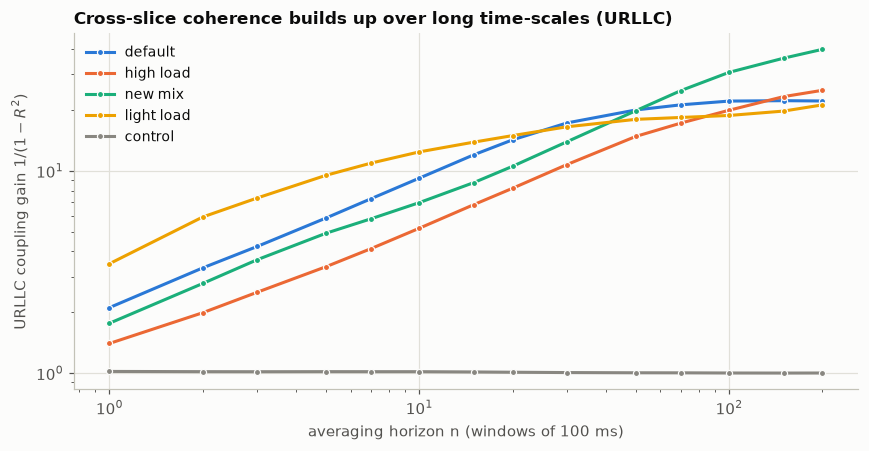

,1,2,3,5,7,10,15,20,30,50,70,100,150,200
default,2.1,3.3,4.2,5.9,7.3,9.2,12.0,14.2,17.3,20.0,21.2,22.2,22.3,22.2
high_load,1.4,2.0,2.5,3.4,4.1,5.2,6.8,8.2,10.8,14.8,17.3,20.0,23.3,25.0
new_mix,1.8,2.8,3.6,4.9,5.8,7.0,8.8,10.5,14.0,19.9,25.0,30.7,36.1,39.9
light_load,3.5,5.9,7.3,9.5,10.9,12.4,13.9,15.0,16.5,18.0,18.4,18.8,19.8,21.2
control,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [4]:
NS = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 70, 100, 150, 200]
curves = {n: [single(long_run_cov(R[n]["Ztr"], k - 1), 1) for k in NS] for n in SETTINGS}
fig, ax = plt.subplots(figsize=(8, 4.2))
for n in SETTINGS:
    ax.plot(NS, curves[n], marker="o", ms=4, color=COLOR[n], label=NICE_SET[n], mec=SURFACE, mew=0.8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("averaging horizon n (windows of 100 ms)")
ax.set_ylabel(r"URLLC coupling gain $1/(1-R^2)$")
ax.set_title("Cross-slice coherence builds up over long time-scales (URLLC)")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save_fig(fig, "fig1_coherence_horizon")
plt.show()
pd.DataFrame(curves, index=NS).T.round(1)

**What the coherence curves show: each setting has its own time-scale of shared noise**

- **Light load starts high and saturates early.** Its gain is 3.5 at $n = 1$ and 12 at $n = 10$ (1 s), and it approaches 18–21 after about 5 s. With steadier capacity and small bursts, what the slices share is fast.
- **Default saturates near 22 by about 10 s.**
- **High load and the new mix are still rising at 20 s** (25 and 40). Their large, slow eMBB bursts make the slices coherent only over long times.
- **The control is flat at 1.**

So "the coherence at zero frequency" is a limit that a detector reaches only if it integrates over long enough times.

## 3. Delays in every setting

In [5]:
piv = sweep.pivot_table(index=["setting", "scenario", "strength"], columns="detector", values="delay_mean_s")[DETS]
piv = piv.reindex(SETTINGS, level=0)
piv.round(2)

detector                                 per-slice  bank, Sigma  bank, Sigma_LR  bank, VAR
setting scenario               strength                                                   
default mmtc_storm             0.03          24.52        23.68           13.34       5.83
                               0.10          13.92         2.91            0.92       0.69
                               0.25           1.66         0.14            0.16       0.23
                               0.50           0.22         0.10            0.10       0.10
                               1.00           0.10         0.10            0.10       0.10
...                                            ...          ...             ...        ...
control urllc_weight_misconfig 0.03           1.80         1.51            1.54       1.49
                               0.10           0.32         0.29            0.30       0.28
                               0.25           0.11         0.11            0.11       0.11
                               0.50           0.10         0.10            0.10       0.10
                               1.00           0.10         0.10            0.10       0.10

[75 rows x 4 columns]

In [6]:
fnd = sweep.pivot_table(index=["setting", "scenario", "strength"], columns="detector", values="detected")[DETS]
fnd.reindex(SETTINGS, level=0).round(2)

detector                                 per-slice  bank, Sigma  bank, Sigma_LR  bank, VAR
setting scenario               strength                                                   
default mmtc_storm             0.03           0.33         0.41            0.83        1.0
                               0.10           0.83         1.00            1.00        1.0
                               0.25           1.00         1.00            1.00        1.0
                               0.50           1.00         1.00            1.00        1.0
                               1.00           1.00         1.00            1.00        1.0
...                                            ...          ...             ...        ...
control urllc_weight_misconfig 0.03           1.00         1.00            1.00        1.0
                               0.10           1.00         1.00            1.00        1.0
                               0.25           1.00         1.00            1.00        1.0
                               0.50           1.00         1.00            1.00        1.0
                               1.00           1.00         1.00            1.00        1.0

[75 rows x 4 columns]

## 4. Measured gain against the rule

For each setting and local fault we take the weakest strength at which per-slice detection finds at least 80% of faults. There we compute:
- the measured gain of each coupled detector (from mean and from median delays);
- the instantaneous prediction $G_{\text{inst}}$ ($\Sigma$);
- the zero-frequency prediction $G_{\text{DC}}$ ($\Sigma_{LR}$, $L = 50$);
- the VAR-implied zero-frequency prediction.

All predictions use the fault's measured shift $d$.

In [7]:
med = sweep.pivot_table(index=["setting", "scenario", "strength"], columns="detector", values="delay_median_s")
rows = []
for n in SETTINGS:
    for scen in LOCAL:
        s = min(v for v in STRENGTHS if fnd.loc[(n, scen, v), "per-slice"] >= 0.8)
        d = R[n]["shifts"][(scen, s)]
        p, q = piv.loc[(n, scen, s)], med.loc[(n, scen, s)]
        rows.append(dict(setting=n, scenario=scen, strength=s,
                         delay_per_slice=p["per-slice"], delay_var=p["bank, VAR"],
                         gain_sigma=p["per-slice"] / p["bank, Sigma"], gain_lr=p["per-slice"] / p["bank, Sigma_LR"],
                         gain_var=p["per-slice"] / p["bank, VAR"], gain_var_median=q["per-slice"] / q["bank, VAR"],
                         pred_inst=pred_gain(d, R[n]["Sigma"]), pred_dc=pred_gain(d, R[n]["SLR"]),
                         pred_dc_var=pred_gain(d, R[n]["SLR_var"])))
G = pd.DataFrame(rows)
G["ratio_dc"] = G.gain_var / G.pred_dc
G["ratio_inst"] = G.gain_var / G.pred_inst
G.to_csv(OUT / "gains.csv", index=False)
G.round(2)

,setting,scenario,strength,delay_per_slice,delay_var,gain_sigma,gain_lr,gain_var,gain_var_median,pred_inst,pred_dc,pred_dc_var,ratio_dc,ratio_inst
0,default,urllc_surge,0.10,11.60,0.62,3.49,13.31,18.59,16.50,1.97,17.98,23.69,1.03,9.46
1,default,mmtc_storm,0.10,13.92,0.69,4.78,15.11,20.28,16.50,2.48,23.85,31.58,0.85,8.17
2,default,urllc_weight_misconfig,0.10,7.50,0.31,18.93,28.02,24.23,21.33,2.80,30.40,37.06,0.80,8.66
3,high_load,urllc_surge,0.10,10.30,0.54,1.37,7.16,19.23,16.00,1.31,12.53,26.43,1.53,14.67
4,high_load,mmtc_storm,0.10,14.23,0.67,2.06,11.80,21.28,19.07,1.58,15.43,32.47,1.38,13.47
5,high_load,urllc_weight_misconfig,0.10,4.10,0.29,7.65,8.99,14.36,10.50,1.81,24.36,43.67,0.59,7.95
6,new_mix,urllc_surge,0.10,9.21,0.35,3.98,10.16,26.45,24.67,1.81,20.96,62.42,1.26,14.60
7,new_mix,mmtc_storm,0.25,2.58,0.17,23.30,21.49,15.27,7.50,1.95,20.99,60.52,0.73,7.82
8,new_mix,urllc_weight_misconfig,0.10,7.14,0.22,22.99,28.77,32.68,29.00,2.61,37.05,99.06,0.88,12.55
9,light_load,urllc_surge,0.10,4.93,0.78,4.31,5.80,6.36,3.71,3.11,15.24,16.97,0.42,2.05


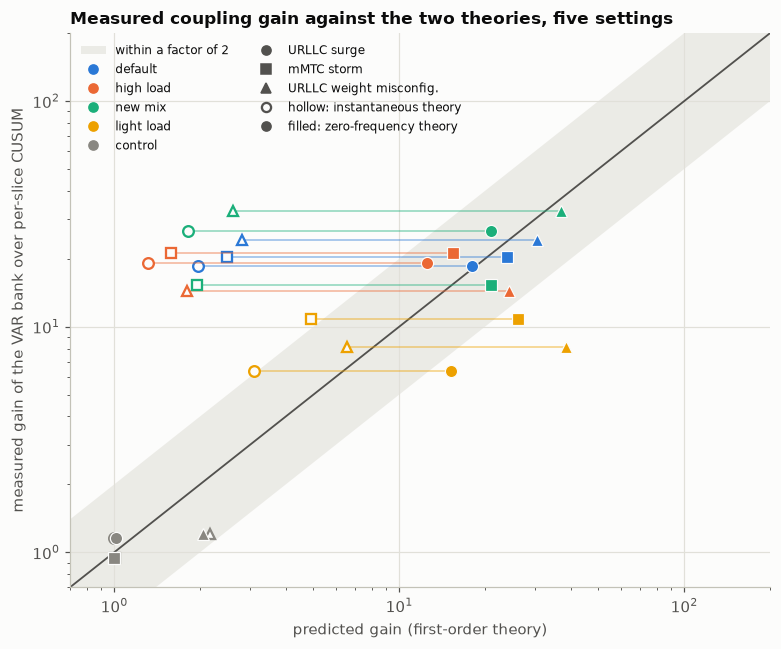

within a factor of 2: zero-frequency 12/15, instantaneous 4/15
Spearman rank correlation, measured vs predicted: zero-frequency 0.52, instantaneous 0.14


ratio_dc       ratio_inst       
                min   max        min    max
setting                                    
default        0.80  1.03       8.17   9.46
high_load      0.59  1.53       7.95  14.67
new_mix        0.73  1.26       7.82  14.60
light_load     0.21  0.42       1.24   2.21
control        0.59  1.14       0.56   1.16

In [8]:
fig, ax = plt.subplots(figsize=(7.2, 6))
lo, hi = 0.7, 200
xs = np.array([lo, hi])
ax.fill_between(xs, xs / 2, xs * 2, color=GRID, alpha=0.6, lw=0, label="within a factor of 2")
ax.plot(xs, xs, color=INK2, lw=1.2)
MARK = {"urllc_surge": "o", "mmtc_storm": "s", "urllc_weight_misconfig": "^"}
for _, r in G.iterrows():
    ax.plot([r.pred_inst, r.pred_dc], [r.gain_var, r.gain_var], color=COLOR[r.setting], lw=1, alpha=0.5)
    ax.plot(r.pred_inst, r.gain_var, marker=MARK[r.scenario], color=COLOR[r.setting], mfc=SURFACE, ms=7, mew=1.5)
    ax.plot(r.pred_dc, r.gain_var, marker=MARK[r.scenario], color=COLOR[r.setting], ms=8, mec=SURFACE, mew=0.8)
for n in SETTINGS:
    ax.plot([], [], "o", color=COLOR[n], label=NICE_SET[n])
for scen, mk in MARK.items():
    ax.plot([], [], mk, color=INK2, label=NICE[scen])
ax.plot([], [], "o", color=INK2, mfc=SURFACE, mew=1.5, label="hollow: instantaneous theory")
ax.plot([], [], "o", color=INK2, label="filled: zero-frequency theory")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("predicted gain (first-order theory)")
ax.set_ylabel("measured gain of the VAR bank over per-slice CUSUM")
ax.set_title("Measured coupling gain against the two theories, five settings")
ax.legend(loc="upper left", fontsize=8, ncol=2)
fig.tight_layout()
save_fig(fig, "fig2_measured_vs_predicted")
plt.show()

within2 = lambda r: ((r > 0.5) & (r < 2)).sum()
print(f"within a factor of 2: zero-frequency {within2(G.ratio_dc)}/{len(G)}, instantaneous {within2(G.ratio_inst)}/{len(G)}")
print("Spearman rank correlation, measured vs predicted: zero-frequency %.2f, instantaneous %.2f"
      % (stats.spearmanr(G.gain_var, G.pred_dc)[0], stats.spearmanr(G.gain_var, G.pred_inst)[0]))
G.groupby("setting", sort=False)[["ratio_dc", "ratio_inst"]].agg(["min", "max"]).round(2)

**What Section 4 shows: the rule predicts the gain in three of four coupled settings and in the control, but not at light load**

- **Control: passes.** The rule predicts no gain (1.0–2.1) and there is essentially none (0.94–1.21×). Coupling is useless when the slices share no noise, as the rule says.
- **Default, high load and new mix: passes.** The VAR bank is 14–33× faster than per-slice CUSUM. The zero-frequency rule predicts 12.5–37, with measured/predicted between 0.59 and 1.53. The instantaneous theory predicts 1.3–2.8, eight to fifteen times too little, in every case.
- **Light load: fails.** The measured gain is 6.4–10.8× against a predicted 15–39 (measured/predicted 0.21–0.42). There the instantaneous theory happens to be closer (3.1–6.5).
- **Overall:**
  - the zero-frequency rule is within a factor of 2 of the measured gain in 12 of 15 cases, the instantaneous one in 4 of 15;
  - the rank correlation between predicted and measured gain is 0.52 against 0.14, but 15 cases is little evidence.
- **The VAR-implied estimate over-predicts** where it disagrees with the Bartlett estimate (high load, new mix: 26–99). The Bartlett window $L = 50$ was fixed in notebook 09 before these settings existed, so it was not tuned to fit them. But the rule is clearly only as good as the estimate of $\Sigma_{LR}$.
- **The misses are where detection is fast.** The per-slice detector needs only 2.8–6.7 s at light load. First-order theory describes long delays, and a short detection time cannot use coherence that builds up over longer times (Section 2). Section 5 tests this.

## 5. Exploratory: does the detection time-scale explain the misses?

A detector that alarms after $n$ windows accumulates only the noise of those $n$ windows. Section 2 shows that the coherence at short horizons is far below its zero-frequency value. We tried two time-scale corrections, in this order; (b) was devised after (a) failed. Both are reported as they came out, and neither was tuned:
- **(a) bank horizon:** both rates are computed from the covariance of $n_b$-window averages, with $n_b$ the VAR bank's mean delay in windows;
- **(b) own horizons:** the VAR bank's rate is the zero-frequency one (its increments are white, so its noise does not build up), and the per-slice rate uses the covariance at the per-slice detector's own delay $n_{ps}$.

In [9]:
rows = []
for _, r in G.iterrows():
    Z, d = R[r.setting]["Ztr"], R[r.setting]["shifts"][(r.scenario, r.strength)]
    nb = max(1, int(round(r.delay_var / 0.1)))
    nps = max(1, int(round(r.delay_per_slice / 0.1)))
    Snb, Snps = long_run_cov(Z, nb - 1), long_run_cov(Z, nps - 1)
    rows.append(dict(setting=r.setting, scenario=r.scenario, measured=r.gain_var, pred_dc=r.pred_dc,
                     n_bank=nb, pred_bank_horizon=pred_gain(d, Snb), n_per_slice=nps,
                     pred_own_horizons=(d @ np.linalg.solve(R[r.setting]["SLR"], d)) / np.max(d**2 / np.diag(Snps))))
H = pd.DataFrame(rows)
H.to_csv(OUT / "horizon_check.csv", index=False)
H.round(2)

,setting,scenario,measured,pred_dc,n_bank,pred_bank_horizon,n_per_slice,pred_own_horizons
0,default,urllc_surge,18.59,17.98,6,5.99,116,17.36
1,default,mmtc_storm,20.28,23.85,7,8.77,139,22.53
2,default,urllc_weight_misconfig,24.23,30.40,3,5.82,75,30.06
3,high_load,urllc_surge,19.23,12.53,5,2.99,103,13.21
4,high_load,mmtc_storm,21.28,15.43,7,4.49,142,16.00
5,high_load,urllc_weight_misconfig,14.36,24.36,3,3.46,41,23.83
6,new_mix,urllc_surge,26.45,20.96,3,3.74,92,21.35
7,new_mix,mmtc_storm,15.27,20.99,2,3.04,26,21.45
8,new_mix,urllc_weight_misconfig,32.68,37.05,2,4.19,71,37.87
9,light_load,urllc_surge,6.36,15.24,8,10.00,49,15.23


**What Section 5 shows: the light-load miss stays unexplained**

- **(a) Bank horizon fails overall.** It moves light load closer (10–15 against measured 6–11), but predicts only 3–9 in the other coupled settings, where 14–33 was measured. Evaluating the noise at the coupled detector's short horizon throws away exactly the slow coherence that the VAR bank exploits.
- **(b) Own horizons changes almost nothing** (within about 10% of $G_{\text{DC}}$ everywhere), because a single slice's own noise builds up little over time.
- **A remaining hypothesis, not tested here, is the fixed reference value.** Every CUSUM uses the reference value $k = \tfrac12$. The ratio of delays equals the ratio of information rates only when each detector is matched to the fault size. When a detector's drift is well above $k$, delays scale with the shift, not with its square, so gains shrink towards the square root of the information ratio. At light load the per-slice detector is already fast, which fits this. A test would use detectors matched to each fault (an oracle $k$).

In [10]:
# Export tables and key numbers for report/main.tex
f1 = lambda v: "--" if pd.isna(v) else f"{v:.1f}"
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
t = settings[["setting", "load", "utilisation", "lat_eMBB", "lat_URLLC", "lat_mMTC", "VAR_p",
              "inst_URLLC", "DC_URLLC", "DCvar_URLLC", "inst_mMTC", "DC_mMTC", "DCvar_mMTC"]].copy()
t["load"] = t.load.map(lambda v: f"{100 * v:.0f}\\%")
t["utilisation"] = t.utilisation.map(lambda v: f"{100 * v:.0f}\\%")
for c in ["lat_eMBB", "lat_URLLC", "lat_mMTC"]:
    t[c] = t[c].map(lambda v: f"{v:.2f}")
for c in t.columns[7:]:
    t[c] = t[c].map(f1)
t.columns = ["setting", "load", "util.", "eMBB", "URLLC", "mMTC", "$p$", "inst.", "DC", "DC (VAR)", "inst.", "DC", "DC (VAR)"]
save_tex_table(t, "settings", "lrrrrrrrrrrrr")

t = G[["setting", "scenario", "strength", "delay_per_slice", "delay_var", "gain_sigma", "gain_lr", "gain_var",
       "gain_var_median", "pred_inst", "pred_dc", "pred_dc_var"]].copy()
t["setting"] = [NICE_SET[v] if i == 0 or v != t.setting.iloc[i - 1] else "" for i, v in enumerate(t.setting)]
t["scenario"] = t.scenario.map(NICE)
t["strength"] = t.strength.map(lambda v: f"{v:g}")
for c in ["delay_per_slice", "delay_var"]:
    t[c] = t[c].map(f2)
for c in t.columns[5:]:
    t[c] = t[c].map(f1)
t.columns = ["setting", "fault", "$s$", "per-slice (s)", "VAR bank (s)", r"bank $\Sigma$", r"bank $\Sigma_{LR}$",
             "VAR bank", "VAR (median)", "inst.", "DC", "DC (VAR)"]
save_tex_table(t, "gains", "lllrrrrrrrrr")

t = H.copy()
t["setting"] = [NICE_SET[v] if i == 0 or v != t.setting.iloc[i - 1] else "" for i, v in enumerate(t.setting)]
t["scenario"] = t.scenario.map(NICE)
for c in ["measured", "pred_dc", "pred_bank_horizon", "pred_own_horizons"]:
    t[c] = t[c].map(f1)
t.columns = ["setting", "fault", "measured", "DC", "$n_b$", "(a) bank horizon", "$n_{ps}$", "(b) own horizons"]
save_tex_table(t, "horizon", "llrrrrrr")

coupled = G[G.setting.isin(["default", "high_load", "new_mix"])]
light, ctrl = G[G.setting == "light_load"], G[G.setting == "control"]
save_tex_numbers({
    "SlWithinDc": f"{within2(G.ratio_dc)}", "SlWithinInst": f"{within2(G.ratio_inst)}", "SlCases": f"{len(G)}",
    "SlRatioCoupledMin": f2(coupled.ratio_dc.min()), "SlRatioCoupledMax": f2(coupled.ratio_dc.max()),
    "SlRatioLightMin": f2(light.ratio_dc.min()), "SlRatioLightMax": f2(light.ratio_dc.max()),
    "SlGainCoupledMin": f1(coupled.gain_var.min()), "SlGainCoupledMax": f1(coupled.gain_var.max()),
    "SlInstCoupledMax": f1(coupled.pred_inst.max()),
    "SlGainLightMin": f1(light.gain_var.min()), "SlGainLightMax": f1(light.gain_var.max()),
    "SlPredLightMin": f1(light.pred_dc.min()), "SlPredLightMax": f1(light.pred_dc.max()),
    "SlGainCtrlMin": f2(ctrl.gain_var.min()), "SlGainCtrlMax": f2(ctrl.gain_var.max()),
    "SlSpearmanDc": f2(stats.spearmanr(G.gain_var, G.pred_dc)[0]),
    "SlSpearmanInst": f2(stats.spearmanr(G.gain_var, G.pred_inst)[0]),
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("11_*")))

exported: ['11_gains.tex', '11_horizon.tex', '11_numbers.tex', '11_settings.tex']


## Summary

- **The zero-frequency rule generalises in part.**
  - It correctly predicts **no** gain where the slices share no slow noise (control).
  - It predicts the gain to within a factor of 1.7 in the three settings with large slow shared noise (default, high load, new mix: 14–33× measured).
  - It **over-predicts by 2.4–4.8×** at light load, where detection is fast and the shared noise is fast.
- **The instantaneous theory, the usual way to reason about coupling, is wrong wherever coupling matters.** It is 8–15× too low in the three strongly coupled settings.
- **The rule is an order-of-magnitude design rule, not a precise predictor.** Two things limit it:
  - estimating $\Sigma_{LR}$ is ill-conditioned when $R^2_{\text{DC}} \to 1$ (Bartlett and VAR estimates differ by up to 3×);
  - first-order theory needs long detection delays.
- **Honest claim for a paper.** Under shared-resource slicing the useful coupling lives at low frequency. Instantaneous correlation underestimates it by about an order of magnitude, and a jointly whitened coupled detector realises it, 6–33× faster than per-slice CUSUM in all four settings with shared slow noise. The zero-frequency rule predicts the gain well in three of them and over-predicts in one.
- **Next:**
  - test the fixed-reference hypothesis with matched detectors (oracle $k$);
  - test a horizon-aware prediction (coherence at the detector's integration time) with a pre-registered choice of horizon;
  - ML baselines at the same ARL.